# EN3160 Assignment 2 on Fitting and Alignment

Index No: 230659H

Name: Upekshani T. S.

Github Link: [https://github.com/shalaniupekshani/EN3160-Assignment-2-on-Fitting-and-Alignment](https://github.com/shalaniupekshani/EN3160-Assignment-2-on-Fitting-and-Alignment)

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
from skimage.feature import blob_log
from scipy.ndimage import maximum_filter

In [ ]:
#Load the reduced resolution image
im=cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Couldn't load the sunflower image.")
#Convert BGR to RGB and grayscale
im_rgb=cv.cvtColor(im,cv.COLOR_BGR2RGB)
gray=cv.cvtColor(im,cv.COLOR_BGR2GRAY)
gray=gray.astype(np.float32)/255.0

In [ ]:
sigmas=np.geomspace(0.01,11.0,100)    #sigma values to investigate
scale_space=[]
for sigma in sigmas:
    blurred=cv.GaussianBlur(gray,(0,0),sigmaX=float(sigma),sigmaY=float(sigma))
    laplacian=cv.Laplacian(blurred,cv.CV_32F,ksize=1)
    normalized_log=(sigma**2)*laplacian
    output=normalized_log**2
    scale_space.append(output)
scale_space = np.stack(scale_space, axis=0)
#print(scale_space)

In [ ]:
local_max = maximum_filter(scale_space, size=(3, 3, 3))
threshold_rel = 0.62
threshold = threshold_rel * np.max(scale_space)
peak_mask = (scale_space == local_max) & (scale_space > threshold)
scale_idx, ys, xs = np.where(peak_mask)
circles = []
for i, y, x in zip(scale_idx, ys, xs):
    sigma_value = float(sigmas[i])
    radius = int(round(2 * sigma_value))
    circles.append({"x": int(x),"y": int(y),"sigma": sigma_value,"radius": radius,"response": float(scale_space[i, y, x])})
print("No. of detected blobs:", len(circles))

No. of detected blobs: 46


,Rank,x,y,Sigma,Radius,Response
0,1,0,275,7.1956,14,0.119400
1,2,282,338,7.1956,14,0.122425
2,3,106,255,5.8197,12,0.131827
3,4,179,327,5.8197,12,0.118464
4,5,178,261,5.4223,11,0.122999
5,6,189,240,4.3855,9,0.131351
6,7,63,243,4.3855,9,0.127315
7,8,70,286,4.3855,9,0.123397
8,9,161,290,4.3855,9,0.132428
9,10,274,258,4.7069,9,0.118279


(np.float64(-0.5), np.float64(359.5), np.float64(359.5), np.float64(-0.5))

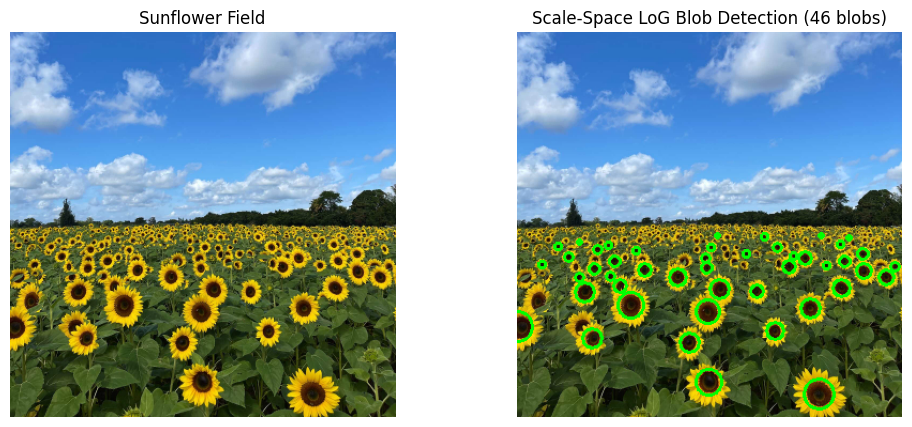

In [ ]:
result = cv.cvtColor(im, cv.COLOR_BGR2RGB)

circles.sort(key=lambda c: c["radius"], reverse=True) #Sort circles by radius.

largest_circles = []
for rank, c in enumerate(circles[:10], start=1):
    largest_circles.append({"Rank": rank,"x": c["x"],"y": c["y"],"Sigma": round(c["sigma"], 4),"Radius": c["radius"],"Response": round(c["response"], 6)})
df = pd.DataFrame(largest_circles)
display(df)

for circle in circles:
    center = (circle["x"], circle["y"])
    radius = circle["radius"]
    cv.circle(result,center,radius,(0, 255, 0),2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(im_rgb)
axes[0].set_title("Sunflower Field")
axes[0].axis('off')
axes[1].imshow(result)
axes[1].set_title(f"Scale-Space LoG Blob Detection ({len(circles)} blobs)")
axes[1].axis('off')

### Blob Detection Using Laplacian of Gaussian (LoG)

The sunflower field image was converted to grayscale and processed using the Laplacian of Gaussian (LoG) method at 100 geometrically spaced scales, ranging from sigma = 0.01 to 11.0 pixels. The squared, scale-normalized LoG response was used to detect blobs. Scale-space extrema were identified using a 3 x 3 x 3 maximum filter with a relative threshold of 0.62. Circles were drawn at the detected blob centres with radius = 2 x sigma.

**Parameters:**

* Sigma range: 0.01 to 11.0 pixels
* Number of scales: 400
* Laplacian kernel size: 1
* Relative threshold: 0.62
* Circle radius: 2 x sigma

**Largest detected circles:**

The largest detected circles have a radius of 14 pixels, with sigma = 7.1956 pixels.

Question 2

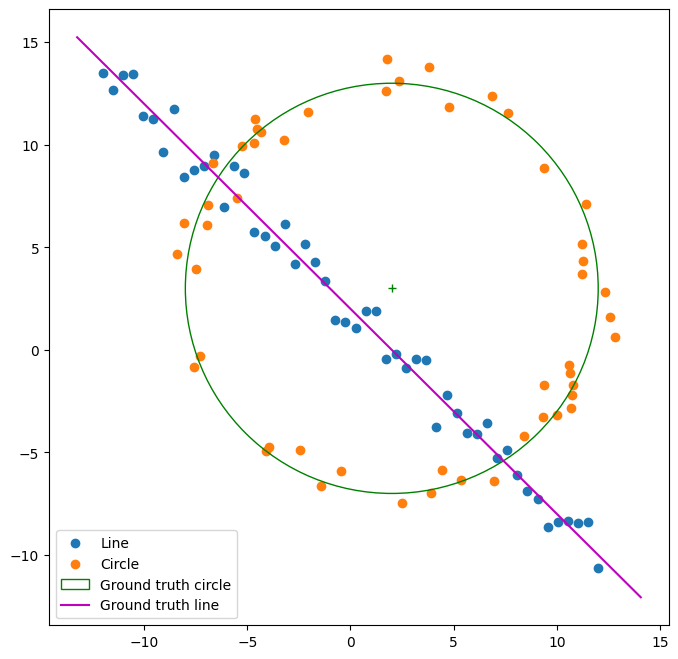

In [ ]:
# Part a
from scipy .optimize import minimize
from scipy import linalg
import matplotlib . pyplot as plt

# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt , y0_gt = 2, 3 # Center
s = r/16
t = np.random.uniform(0, 2*np.pi , half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
X = np.vstack((X_circ , X_line )) # All points
fig , ax = plt.subplots(1,1, figsize =(8,8))
ax. scatter (X_line [: ,0] , X_line [: ,1] , label= 'Line' )
ax. scatter ( X_circ [: ,0] , X_circ [: ,1] , label= 'Circle' )
circle_gt = plt . Circle ((x0_gt ,y0_gt) , r , color= 'g' , fill=False , label='Ground truth circle' )
ax. add_patch( circle_gt )
ax. plot (( x0_gt) , (y0_gt) , '+' , color= 'g' )
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt . plot (x_ , y_, color= 'm' , label='Ground truth line' )
plt . legend ()

In [ ]:
def two_points_lines(p1, p2):
    dir = p2 - p1
    a = dir[1]
    b = -dir[0]
    norm = np.hypot(a, b)
    if norm > 0:
        a /= norm
        b /= norm
        d = a * p1[0] + b * p1[1]
        return np.array([a, b, d])
    else:
        return None

def error(X, model):
    a, b, d = model
    return np.abs(a * X[:, 0] + b * X[:, 1] - d)

def ransac_line(X, iter=2000, threshold=1.5,min_inlier=40, seed=0):
    rng = np.random.default_rng(seed)
    best_model = None
    best_inlier = None
    best_sample=None

    for _ in range(iter):
        idx = rng.choice(len(X), size=2, replace=False)  # Randomly sample two distinct points
        model = two_points_lines(X[idx[0]], X[idx[1]])
        if model is None:
            continue
        errors = error(X, model)
        inliers = errors < threshold
        if np.sum(inliers) < min_inlier:
            continue    # Reject candidates
        if (best_inlier is None or np.sum(inliers) > np.sum(best_inlier)):
            best_model = model
            best_inlier = inliers
            best_sample=idx.copy()
    if best_model is None:
        raise RuntimeError("No valid line found.")
    return best_model, best_inlier,best_sample

In [ ]:
line_model, line_inliers, line_sample = ransac_line(X)

print("Estimated line [a, b, d]:", line_model)
print("Number of inliers:", np.sum(line_inliers))
print("Normal vector length:",
      np.hypot(line_model[0], line_model[1]))

X_line_inliers = X[line_inliers]
X_remaining = X[~line_inliers]
X_line_sample=X[line_sample]

Estimated line [a, b, d]: [-0.69007633 -0.72373659 -1.49862447]
Number of inliers: 55
Normal vector length: 1.0


In [ ]:
#best fit line
x_plot=np.linspace(X[:,0].min()-2,X[:,0].max()+2,300)
a,b,d=line_model
if abs(b)>0:
    y_best_line=(d-a*x_plot)/b

In [ ]:
# Part b
def three_points_circle(p1,p2,p3):
    A=2*np.array([p2-p1,p3-p1])
    rhs=np.array([np.dot(p2,p2)-np.dot(p1,p1),np.dot(p3,p3)-np.dot(p1,p1)])
    if abs(np.linalg.det(A))<=0:
        return None
    try:
        xc,yc=np.linalg.solve(A,rhs)
    except np.linalg.LinAlgError:
        return None
    center=np.array([xc,yc])
    r=np.linalg.norm(p1-center)
    return np.array([xc,yc,r])

def circle_error(X,model):
    xc,yc,r=model
    distances=np.sqrt((X[:,0]-xc)**2+(X[:,1]-yc)**2)
    return np.abs(distances-r)

def ransac_circle(X,iter=3000,threshold=1.5,min_inlier=40,seed=1):
    rng=np.random.default_rng(seed)
    best_model=None
    best_inliers=None
    best_sample=None

    for _ in range(iter):
        idx = rng.choice(len(X), size=3, replace=False)  # Randomly sample two distinct points
        model = three_points_circle(X[idx[0]], X[idx[1]],X[idx[2]])
        if model is None:
            continue
        errors = circle_error(X, model)
        inliers = errors < threshold
        if np.sum(inliers) < min_inlier:
            continue    # Reject candidates
        if (best_inliers is None or np.sum(inliers) > np.sum(best_inliers)):
            best_model = model
            best_inliers = inliers
            best_sample=idx.copy()
    if best_model is None:
        raise RuntimeError("No valid circle found.")
    return best_model,best_inliers,best_sample

circle_model,circle_inliers,circle_sample=  ransac_circle(X_remaining,iter=3000,threshold=1.5,min_inlier=40,seed=1)
print("Circle from best RANSAC sample [xc, yc, r]:",circle_model)
print("Number of circle inliers:", np.sum(circle_inliers))
X_circle_inliers = X_remaining[circle_inliers]
X_circle_sample = X_remaining[circle_sample]

Circle from best RANSAC sample [xc, yc, r]: [2.58478352 3.68363379 9.67116926]
Number of circle inliers: 45


In [ ]:
def circle_objective(params,points):
    xc,yc,r=params
    distances=np.sqrt((points[:,0]-xc)**2+(points[:,1]-yc)**2)
    res=distances-r
    return np.sum(res**2)
result=minimize(circle_objective,x0=circle_model,args=(X_circle_inliers,),method="BFGS")
if not result.success:
    print("Optimizer warning:", result.message)
best_circle=result.x
print("Optimized circle [xc, yc, r]:", best_circle)

Optimized circle [xc, yc, r]: [2.00997853 3.1261482  9.93200235]


In [ ]:
# Sample based line
p1, p2 = X_line_sample
sample_model = two_points_lines(p1, p2)
a_s, b_s, d_s = sample_model
if abs(b_s) > 0:
    y_sample_line = (d_s - a_s * x_plot) / b_s

#Draw two circles
theta = np.linspace(0, 2 * np.pi, 400)
# Circle estimated from the best three-point sample
xc_s, yc_s, r_s = circle_model
x_circle_sample = xc_s + r_s * np.cos(theta)
y_circle_sample = yc_s + r_s * np.sin(theta)

# Optimized best-fit circle
xc, yc, r = best_circle
x_circle_best = xc + r * np.cos(theta)
y_circle_best = yc + r * np.sin(theta)

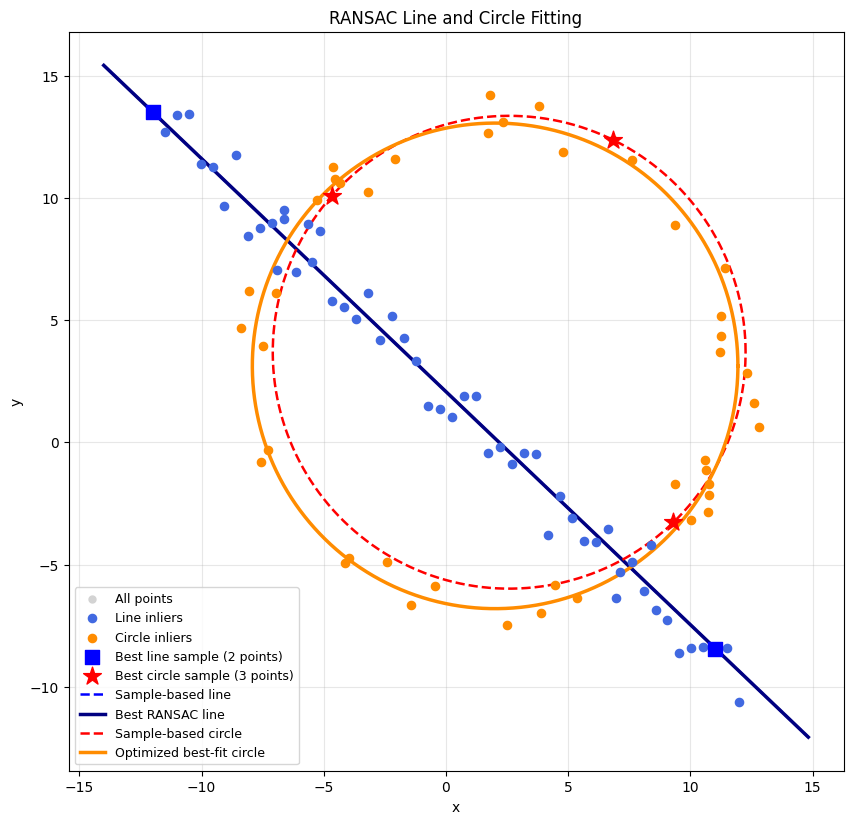

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

# Original point set
ax.scatter(X[:, 0], X[:, 1],color="lightgray", s=25,label="All points", zorder=1)
# Line inliers
ax.scatter(X_line_inliers[:, 0], X_line_inliers[:, 1],color="royalblue", s=35,label="Line inliers", zorder=3)
# Circle inliers
ax.scatter(X_circle_inliers[:, 0], X_circle_inliers[:, 1],color="darkorange", s=35,label="Circle inliers", zorder=3)
# Two points used for the best line sample
ax.scatter(X_line_sample[:, 0], X_line_sample[:, 1],color="blue", marker="s", s=100,label="Best line sample (2 points)", zorder=5)
# Three points used for the best circle sample
ax.scatter(X_circle_sample[:, 0], X_circle_sample[:, 1],color="red", marker="*", s=180,label="Best circle sample (3 points)", zorder=6)
# Sample-based line
if abs(b_s) > 1e-8:
    ax.plot(x_plot, y_sample_line, "b--",linewidth=1.8, label="Sample-based line")
# Best RANSAC line
if abs(b) > 1e-8:
    ax.plot(x_plot, y_best_line, "navy",linewidth=2.5, label="Best RANSAC line")
# Sample-based circle
ax.plot(x_circle_sample, y_circle_sample, "r--",linewidth=1.8, label="Sample-based circle")
# Optimized best-fit circle
ax.plot(x_circle_best, y_circle_best, "darkorange",linewidth=2.5, label="Optimized best-fit circle")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.show()

RANSAC correctly identified the line and circle from the noisy point set using geometric error thresholds and consensus-based model selection. The line was estimated using two randomly sampled points with a unit normal constraint and the circle was estimated using three points. Circle is refined using scipy.optimize.minimize by minimizing the squared radial errors of its inliers. Differences from the ground-truth models were mainly due to noise and inlier selection.

(d) Effect of fitting the circle first: If we fit the circle first, RANSAC can still find the valid circle, but that may sffected by some line point if they fall within the radial error. Removing these points may affect the subsequent line fitting. However, if the circle is correctly identified, fitting it first can also produce good results. Therefore, the fitting order can affect the final estimates depending on the error thresholds, minimum consensus sizes, and point distribution.

Question 3

In [ ]:
def superimpose_image(bg, flag):
    points = []

    def click_point(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append([x, y])
            print(f"Point {len(points)}: ({x}, {y})")
            cv.circle(display, (x, y), 5, (0, 255, 0), -1)
            cv.imshow("Select 4 corners", display)

    # Select four corners on the background
    display = bg.copy()
    cv.namedWindow("Select 4 corners")
    cv.setMouseCallback("Select 4 corners", click_point)
    cv.imshow("Select 4 corners", display)
    cv.waitKey(0)
    cv.destroyAllWindows()

    if len(points) != 4:
        raise ValueError("You must click exactly four points.")

    destination_points = np.float32(points)

    # Define four corners of the overlay image
    h_flag, w_flag = flag.shape[:2]
    source_points = np.float32([
        [0, 0],
        [w_flag - 1, 0],
        [w_flag - 1, h_flag - 1],
        [0, h_flag - 1]
    ])

    # Compute homography
    H = cv.getPerspectiveTransform(
        source_points, destination_points
    )
    print("Homography matrix:\n", H)

    # Warp the overlay image
    h_bg, w_bg = bg.shape[:2]
    warped = cv.warpPerspective(flag, H, (w_bg, h_bg))

    # Blend overlay with background
    mask = np.zeros((h_bg, w_bg), dtype=np.uint8)
    cv.fillConvexPoly(
        mask, destination_points.astype(np.int32), 255
    )

    result = bg.copy()
    result[mask == 255] = warped[mask == 255]

    # Display final composite
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(bg)
    plt.title("Original Background")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(flag)
    plt.title("Overlay")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(result)
    plt.title("Final Composite")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return result

Point 1: (679, 427)
Point 2: (821, 417)
Point 3: (830, 504)
Point 4: (679, 512)
Homography matrix:
 [[ 6.18833678e-02 -4.10055520e-02  6.79000000e+02]
 [-1.13637050e-02  5.77137543e-02  4.27000000e+02]
 [-1.47545744e-05 -6.03910927e-05  1.00000000e+00]]


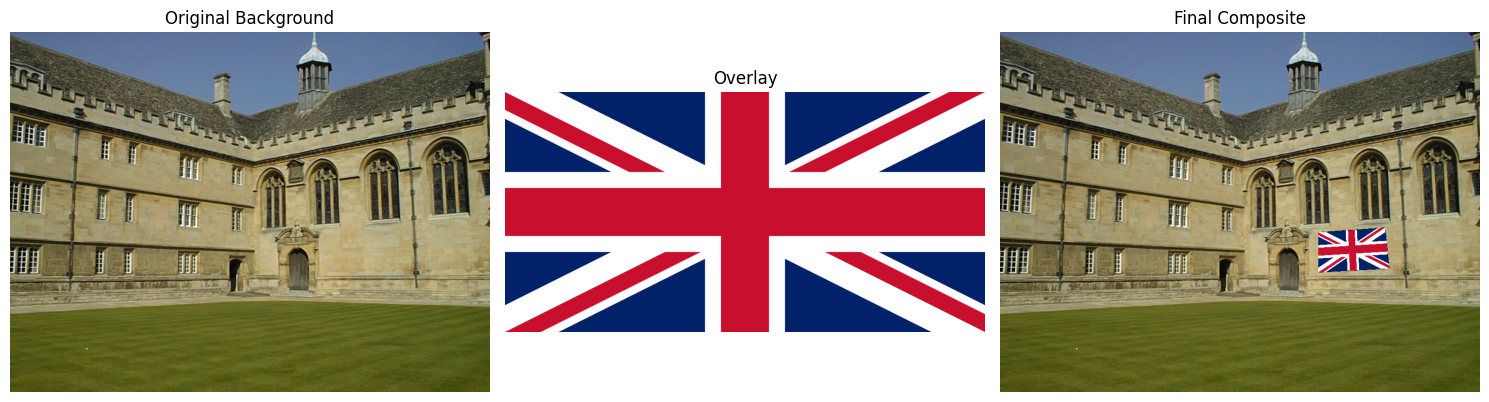

Point 1: (152, 165)
Point 2: (258, 164)
Point 3: (260, 297)
Point 4: (161, 311)
Homography matrix:
 [[3.44768685e-01 3.89173598e-02 1.52000000e+02]
 [4.20054307e-02 3.24913453e-01 1.65000000e+02]
 [2.71927465e-04 1.33177837e-04 1.00000000e+00]]


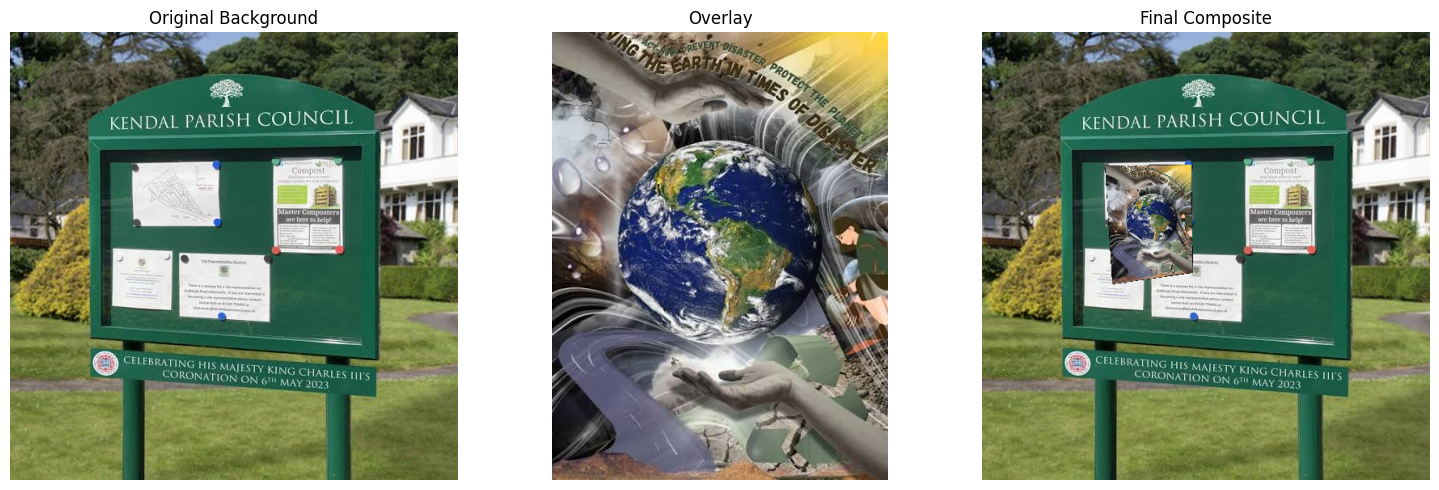

Point 1: (282, 305)
Point 2: (337, 303)
Point 3: (338, 387)
Point 4: (280, 392)
Homography matrix:
 [[ 1.80785965e-01 -3.05323810e-02  2.82000000e+02]
 [ 2.15846818e-02  1.22025309e-01  3.05000000e+02]
 [ 8.93205738e-05 -9.59380579e-05  1.00000000e+00]]


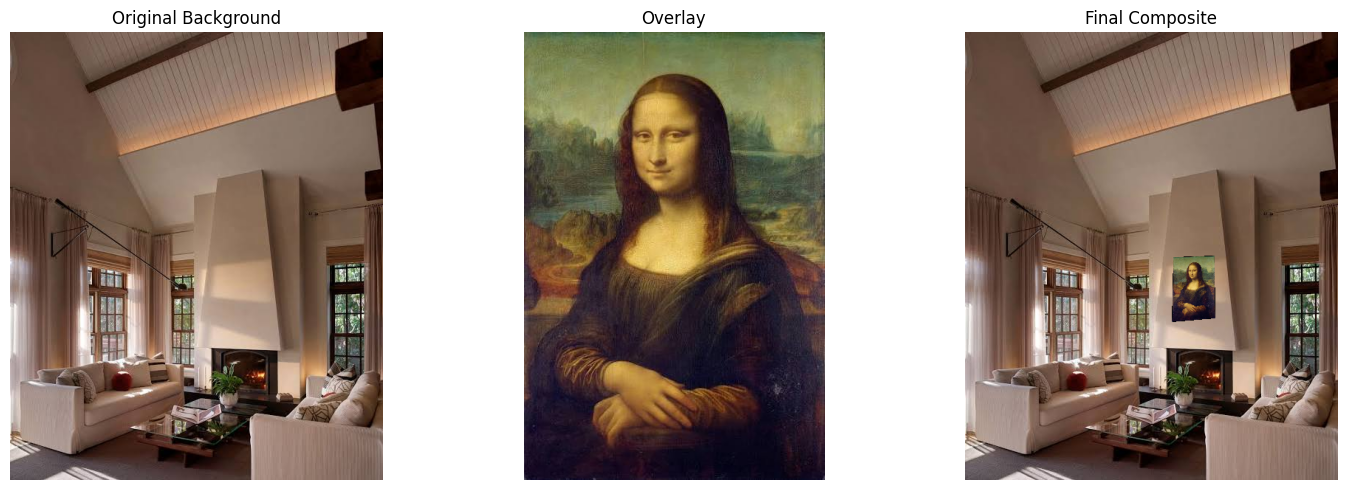

In [ ]:
bg1=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\wadham.jpg'),cv.COLOR_BGR2RGB)
overlay1=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\flag.png'),cv.COLOR_BGR2RGB)
result1 = superimpose_image(bg1, overlay1)

bg2=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\bg2.jpg'),cv.COLOR_BGR2RGB)
overlay2=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\overlay2.jpg'),cv.COLOR_BGR2RGB)
result2 = superimpose_image(bg2, overlay2)

bg3=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\bg3.jpg'),cv.COLOR_BGR2RGB)
overlay3=cv.cvtColor(cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\overlay3.jpg'),cv.COLOR_BGR2RGB)
result3 = superimpose_image(bg3, overlay3)

Here, the 4 points are selected in the architectural image. Then homography matrix is calculated to map the flag image to the selected plane. Then flag image is warped and blended with background image. Accuracy of final result will depend on the precision of slected cornera and the how closely the target surface approximates a plane.

Reasons:  Placing poster on notice board gives a realistic advertising application. Superimposing drawing into the wall represents a practical application of planar homography by visualizing how artwork would look when displayed on a wall.

Question 4

In [ ]:
def align_and_compare(template, pcb):
    # Convert images to grayscale
    template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
    pcb_gray = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)

    #Part a - Detect SIFT features
    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(template_gray, None)
    kp2, des2 = sift.detectAndCompute(pcb_gray, None)

    # Part b - Match features using BFMatcher
    bf = cv.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)
    # Apply Lowe's ratio test
    good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]
    # Find homography using RANSAC
    src_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

    # Part c - Warp PCB image to align with template
    h, w = template.shape[:2]
    aligned = cv.warpPerspective(pcb, H, (w, h))
    # Compute absolute difference
    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)
    difference = cv.absdiff(template_gray, aligned_gray)
    # Draw feature matches
    match_img = cv.drawMatches(template, kp1, pcb, kp2, good_matches, None,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    # Display results
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(match_img, cv.COLOR_BGR2RGB))
    plt.title(f"SIFT Matches: {len(good_matches)}")
    plt.axis("off")
    plt.subplot(1, 3, 2)
    plt.imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
    plt.title("Aligned PCB")
    plt.axis("off")
    plt.subplot(1, 3, 3)
    plt.imshow(difference, cmap="gray")
    plt.title("Difference Image")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close()
    return aligned, difference

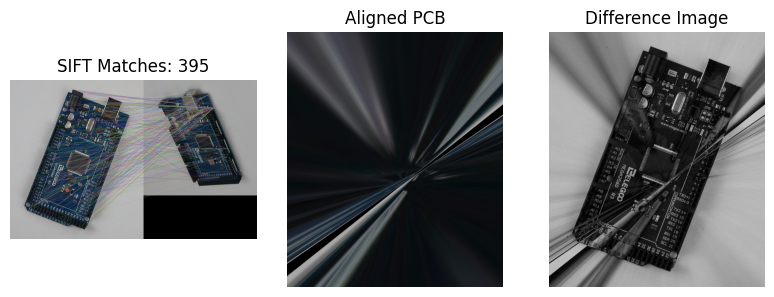

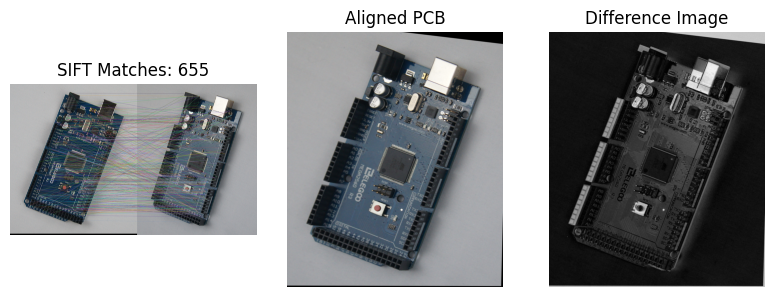

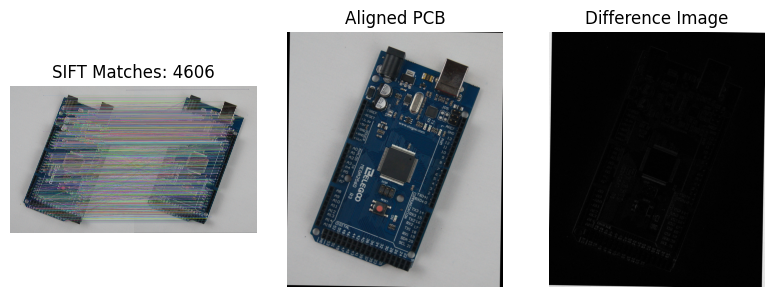

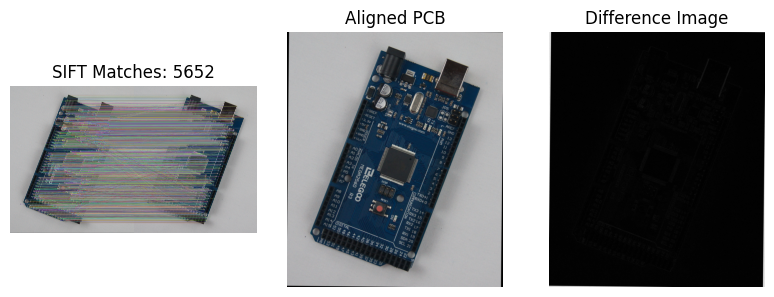

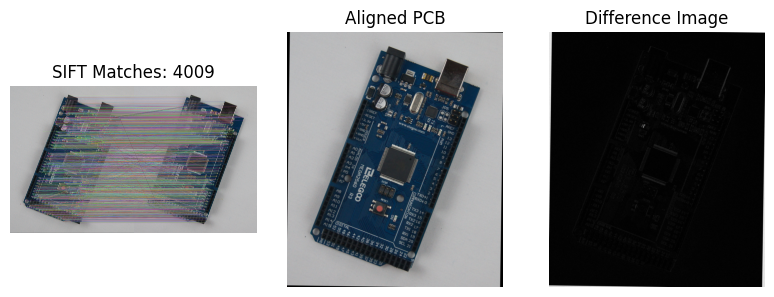

In [ ]:
# Part d
template = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\AECC1.jpg')
pcb1 = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\AAAA1.jpg')
pcb2 = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\ADAD1.jpg')
pcb3 = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\AECC2.jpg')
pcb4 = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\AECC3.jpg')
pcb5 = cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\pcbs\AECC4.jpg')

aligned, difference = align_and_compare(template, pcb1)
aligned, difference = align_and_compare(template, pcb2)
aligned, difference = align_and_compare(template, pcb3)
aligned, difference = align_and_compare(template, pcb4)
aligned, difference = align_and_compare(template, pcb5)

Here, SIFT features were detected and matches between template and PCB images. Then RANSAC is used to estimate homography for perspective alignments. Using absolute pixelwise differences template and the aligned images are matches.

Part e - Some components, such as the USB Type-B port, capacitors, and reset button shows high differences between the aligned PCB image and the reference template. This is occured due to lightning, metallic reflections and misalignments due to perspective transformations.Around component boundaries there may be some pixel intensity variations due to interpolation during image wrapping. So, high difference values do not always indicate defective components, as they may also arise from imaging conditions and imperfect alignment.